# IntelliSense Backtest Analysis
Compare the performance of **Fixed Q-table**, **Q-learning**, and **DQN** strategies across different tickers.

---

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import mplfinance as mpf
import json
import os
import numpy as np
from IPython.display import display, Markdown, HTML

def compute_metrics(trades_df, stock_df):
    """Compute Max DD, Alpha (vs S&P 500), Sharpe Ratio, and Win Rate."""
    
    portfolio_values = trades_df['portfolio_value'].values
    
    # --- Max Drawdown ---
    running_max = np.maximum.accumulate(portfolio_values)
    drawdowns = (running_max - portfolio_values) / running_max
    max_dd = np.max(drawdowns) * 100
    
    # --- Total Return ---
    initial_val = portfolio_values[0]
    final_val = portfolio_values[-1]
    total_return = (final_val - initial_val) / initial_val
    
    # --- Alpha (vs S&P 500 benchmark) ---
    dates = pd.to_datetime(trades_df['date'])
    n_years = (dates.iloc[-1] - dates.iloc[0]).days / 365.25
    sp500_annual_return = 0.10
    sp500_period_return = (1 + sp500_annual_return) ** n_years - 1
    alpha = (total_return - sp500_period_return) * 100
    
    # --- Sharpe Ratio (annualized, daily data, 0% risk-free) ---
    daily_returns = np.diff(portfolio_values) / portfolio_values[:-1]
    if np.std(daily_returns) > 0:
        sharpe = (np.mean(daily_returns) / np.std(daily_returns)) * np.sqrt(252)
    else:
        sharpe = 0.0
    
    # --- Win Rate (only count trades where shares > 0) ---
    real_buys = trades_df[(trades_df['action'] == 'BUY') & (trades_df['shares'] > 0)]
    real_sells = trades_df[(trades_df['action'] == 'SELL') & (trades_df['shares'] > 0)]
    
    wins = 0
    total_trades = 0
    buy_prices = []
    avg_entry = None
    prev_action = None
    
    for _, row in trades_df.iterrows():
        if row['action'] == 'BUY' and row['shares'] > 0:
            if prev_action != 'BUY':
                buy_prices = []
            buy_prices.append(row['price'])
            avg_entry = np.mean(buy_prices)
            prev_action = 'BUY'
        elif row['action'] == 'SELL' and row['shares'] > 0 and avg_entry is not None:
            if row['price'] > avg_entry:
                wins += 1
            total_trades += 1
            prev_action = 'SELL'
    
    win_rate = (wins / total_trades * 100) if total_trades > 0 else 0.0
    
    return {
        'max_dd': max_dd,
        'alpha': alpha,
        'sharpe': sharpe,
        'win_rate': win_rate,
        'total_return': total_return * 100,
        'final_val': final_val,
        'n_buys': len(real_buys),
        'n_sells': len(real_sells),
        'total_trades': total_trades,
        'wins': wins
    }


def build_trade_log(trades_df):
    """Build a styled trade log table showing only executed BUY/SELL (shares > 0)."""
    # Filter to only executed trades (shares > 0)
    active = trades_df[
        (trades_df['action'].isin(['BUY', 'SELL'])) & (trades_df['shares'] > 0)
    ].copy()
    active = active.reset_index(drop=True)
    
    # Format columns
    log = pd.DataFrame()
    log['Date'] = pd.to_datetime(active['date']).dt.strftime('%Y-%m-%d')
    log['Action'] = active['action']
    log['Price'] = active['price'].map('${:,.2f}'.format)
    log['Shares'] = active['shares'].map('{:,.0f}'.format)
    log['Value'] = active['value'].map('${:,.2f}'.format)
    log['Portfolio'] = active['portfolio_value'].map('${:,.2f}'.format)
    
    return log


def style_trade_log(log):
    """Apply color styling to the trade log."""
    def color_action(val):
        if val == 'BUY':
            return 'color: #00c853; font-weight: bold'
        elif val == 'SELL':
            return 'color: #ff1744; font-weight: bold'
        return ''
    
    styled = log.style.applymap(
        color_action, subset=['Action']
    ).set_properties(**{
        'text-align': 'right',
        'font-size': '12px',
        'padding': '4px 8px',
    }).set_table_styles([
        {'selector': 'th', 'props': [
            ('background-color', '#2d2d44'),
            ('color', 'white'),
            ('font-size', '13px'),
            ('text-align', 'center'),
            ('padding', '6px 10px'),
        ]},
        {'selector': 'td', 'props': [
            ('border-bottom', '1px solid #444'),
        ]},
    ]).hide(axis='index')
    
    return styled


def plot_ticker(ticker, method='DQN_Price_Only'):
    """Plot candlestick chart with buy/sell arrows and trade log."""
    results_dir = 'test_results'
    data_dir = 'data'
    
    # --- Load trade history ---
    history_file = os.path.join(results_dir, f'{ticker}_{method}_history.json')
    if not os.path.exists(history_file):
        print(f'No trade history found for {ticker} ({method}) at {history_file}')
        return
    
    with open(history_file, 'r') as f:
        trades = json.load(f)
    trades_df = pd.DataFrame(trades)
    trades_df['date'] = pd.to_datetime(trades_df['date'])
    
    # --- Load weekly stock data ---
    stock_file = os.path.join(data_dir, f'{ticker}_daily_stock_data_5y.csv')
    if not os.path.exists(stock_file):
        print(f'No stock data found for {ticker} at {stock_file}')
        return
    
    stock_df = pd.read_csv(stock_file, index_col=0, parse_dates=True)
    stock_df.columns = [c.strip().title() for c in stock_df.columns]
    stock_df = stock_df.sort_index()
    
    # --- Adjust OHLC prices for stock splits/dividends ---
    if 'Adjusted_Close' in stock_df.columns and 'Close' in stock_df.columns:
        adj_factor = stock_df['Adjusted_Close'] / stock_df['Close']
        adj_factor = adj_factor.replace([np.inf, -np.inf], np.nan).fillna(1.0)
        for col in ['Open', 'High', 'Low', 'Close']:
            stock_df[col] = stock_df[col] * adj_factor
    
    # Filter stock data to backtest period
    start_date = trades_df['date'].min()
    end_date = trades_df['date'].max()
    stock_df = stock_df[(stock_df.index >= start_date) & (stock_df.index <= end_date + pd.Timedelta(days=7))]
    
    if stock_df.empty:
        print(f'No stock data in the backtest date range for {ticker}')
        return
    
    # --- Compute performance metrics ---
    metrics = compute_metrics(trades_df, stock_df)
    
    # --- Extract only EXECUTED BUY and SELL trades (shares > 0) ---
    buys = trades_df[(trades_df['action'] == 'BUY') & (trades_df['shares'] > 0)].copy()
    sells = trades_df[(trades_df['action'] == 'SELL') & (trades_df['shares'] > 0)].copy()
    
    buy_markers = pd.Series(np.nan, index=stock_df.index, dtype=float)
    sell_markers = pd.Series(np.nan, index=stock_df.index, dtype=float)
    
    for _, trade in buys.iterrows():
        trade_date = trade['date']
        nearest_idx = stock_df.index.get_indexer([trade_date], method='nearest')[0]
        if nearest_idx >= 0 and nearest_idx < len(stock_df):
            nearest_date = stock_df.index[nearest_idx]
            buy_markers[nearest_date] = stock_df.loc[nearest_date, 'Low'] * 0.97
    
    for _, trade in sells.iterrows():
        trade_date = trade['date']
        nearest_idx = stock_df.index.get_indexer([trade_date], method='nearest')[0]
        if nearest_idx >= 0 and nearest_idx < len(stock_df):
            nearest_date = stock_df.index[nearest_idx]
            sell_markers[nearest_date] = stock_df.loc[nearest_date, 'High'] * 1.03
    
    # --- Build mplfinance addplots ---
    addplots = []
    if buy_markers.notna().any():
        addplots.append(mpf.make_addplot(
            buy_markers, type='scatter', marker='^', markersize=100,
            color='#00c853', secondary_y=False
        ))
    if sell_markers.notna().any():
        addplots.append(mpf.make_addplot(
            sell_markers, type='scatter', marker='v', markersize=100,
            color='#ff1744', secondary_y=False
        ))
    
    # --- Custom style ---
    custom_style = mpf.make_mpf_style(
        base_mpf_style='nightclouds',
        marketcolors=mpf.make_marketcolors(
            up='#00c853', down='#ff1744',
            edge={'up': '#00c853', 'down': '#ff1744'},
            wick={'up': '#00c853', 'down': '#ff1744'},
            volume='in'
        ),
        facecolor='#1a1a2e',
        edgecolor='#1a1a2e',
        figcolor='#1a1a2e',
        gridcolor='#2d2d44',
        gridstyle='--',
        gridaxis='both',
        y_on_right=True,
        rc={'font.size': 10}
    )
    
    # --- Title with core stats ---
    title = (f'{ticker} — {method.replace("_", " ")} Strategy\n'
             f'Return: {metrics["total_return"]:+.1f}%  |  '
             f'Final: ${metrics["final_val"]:,.0f}  |  '
             f'Buys: {metrics["n_buys"]}  |  Sells: {metrics["n_sells"]}')
    
    # --- Plot ---
    fig, axes = mpf.plot(
        stock_df, type='candle', style=custom_style,
        volume=True, addplot=addplots if addplots else None,
        title=title, figsize=(18, 10),
        tight_layout=False, returnfig=True,
        panel_ratios=(4, 1),
        warn_too_much_data=9999
    )
    
    # Add legend
    ax_main = axes[0]
    ax_main.scatter([], [], marker='^', s=100, color='#00c853', label='BUY')
    ax_main.scatter([], [], marker='v', s=100, color='#ff1744', label='SELL')
    ax_main.legend(loc='upper left', fontsize=12, framealpha=0.7,
                  facecolor='#1a1a2e', edgecolor='#444',
                  labelcolor='white')
    
    # --- Metrics box below the chart ---
    metrics_text = (
        f'Max DD: {metrics["max_dd"]:.1f}%    '
        f'Alpha (vs S&P): {metrics["alpha"]:+.1f}%    '
        f'Sharpe: {metrics["sharpe"]:.2f}    '
        f'Win Rate: {metrics["win_rate"]:.0f}% '
        f'({metrics["wins"]}/{metrics["total_trades"]} trades)'
    )
    
    fig.text(
        0.5, 0.01, metrics_text,
        ha='center', va='bottom', fontsize=13,
        color='white', fontweight='bold',
        fontstyle='italic',
        bbox=dict(boxstyle='round,pad=0.5', facecolor='#2d2d44',
                  edgecolor='#555', alpha=0.9)
    )
    
    fig.subplots_adjust(bottom=0.08)
    plt.show()
    
    # --- Trade Log Table ---
    display(Markdown(f'### {ticker} — Trade Log ({method.replace("_", " ")})'))
    log = build_trade_log(trades_df)
    display(style_trade_log(log))


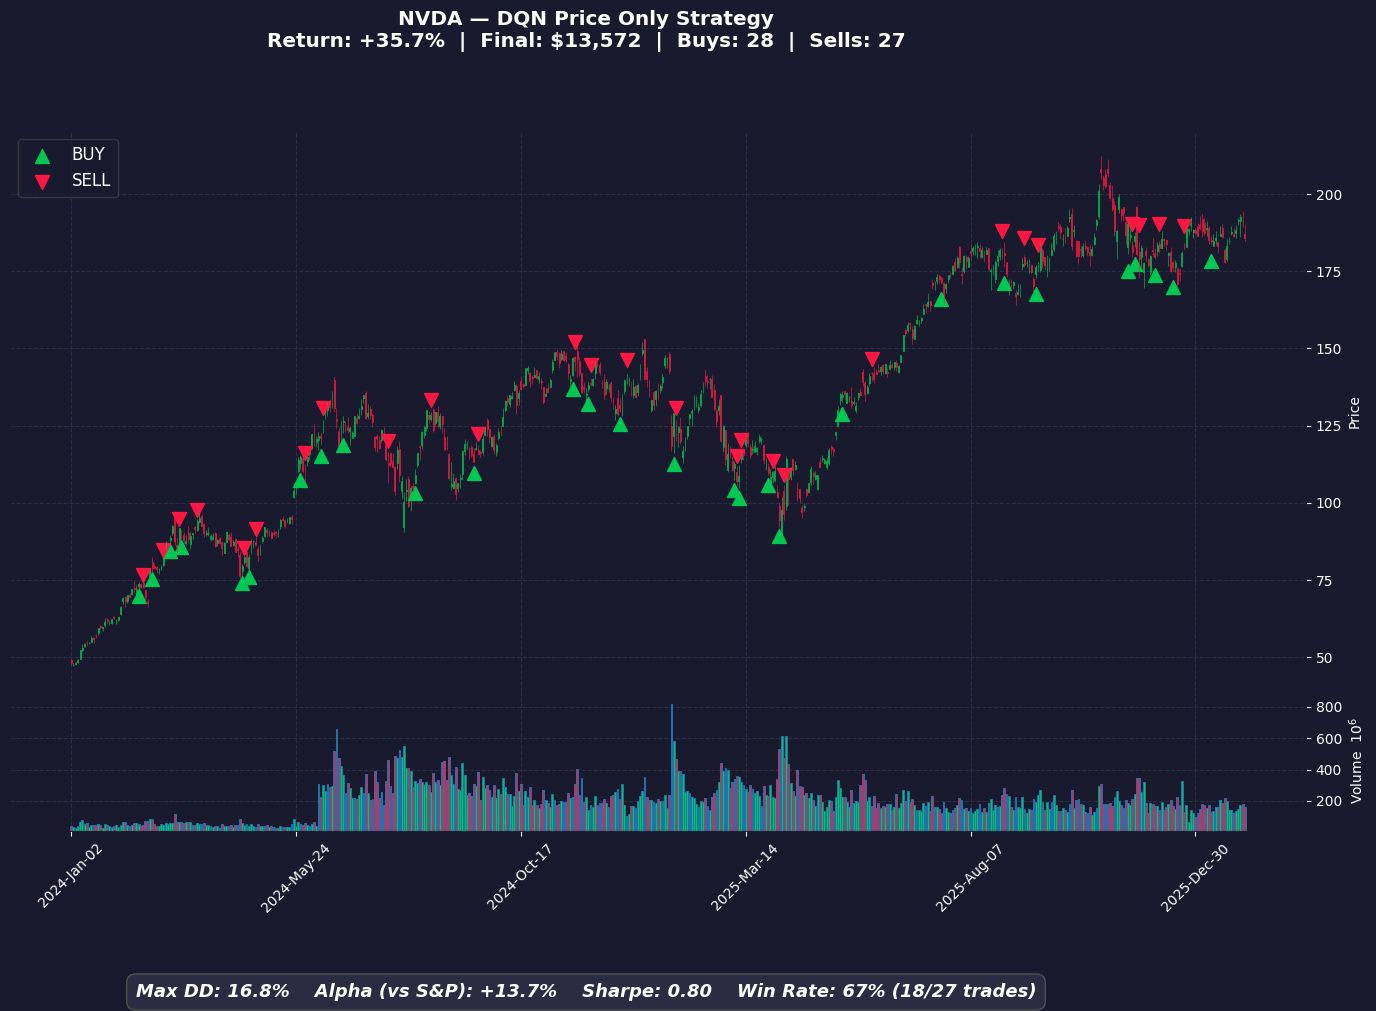

### NVDA — Trade Log (DQN Price Only)

/var/folders/pz/_0kh2t797553_kjgmmh7_0fc0000gn/T/ipykernel_25639/108095686.py:106: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  styled = log.style.applymap(


Date,Action,Price,Shares,Value,Portfolio
2024-02-14,BUY,$73.86,135,"$9,971.02","$9,990.03"
2024-02-16,SELL,$72.57,135,"$9,797.37","$9,806.58"
2024-02-23,BUY,$78.77,124,"$9,767.94","$9,796.81"
2024-03-01,SELL,$82.23,124,"$10,196.99","$10,215.67"
2024-03-06,BUY,$88.66,115,"$10,195.37","$10,205.47"
2024-03-12,SELL,$91.87,115,"$10,564.68","$10,564.22"
2024-03-13,BUY,$90.84,116,"$10,537.71","$10,553.68"
2024-03-22,SELL,$94.24,116,"$10,932.02","$10,937.07"
2024-04-22,BUY,$79.48,137,"$10,888.49","$10,926.18"
2024-04-23,SELL,$82.38,137,"$11,286.27","$11,312.68"


In [16]:
plot_ticker('NVDA', method='DQN_Price_Only')


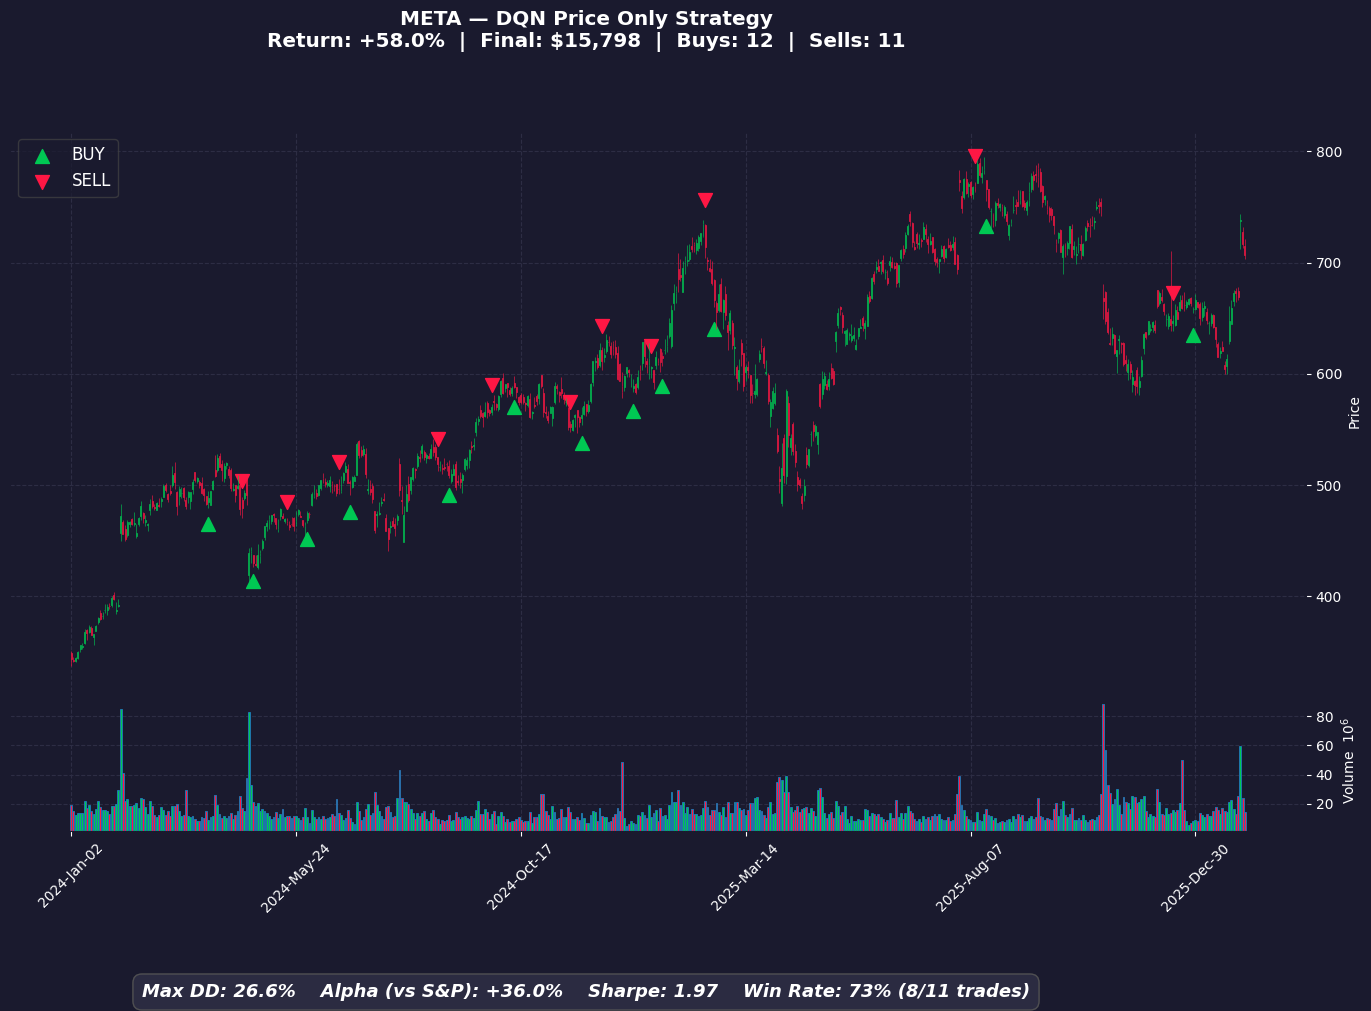

### META — Trade Log (DQN Price Only)

/var/folders/pz/_0kh2t797553_kjgmmh7_0fc0000gn/T/ipykernel_25639/108095686.py:106: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  styled = log.style.applymap(


Date,Action,Price,Shares,Value,Portfolio
2024-04-01,BUY,$488.49,20,"$9,769.81","$9,990.23"
2024-04-22,SELL,$478.93,20,"$9,578.53","$9,789.37"
2024-04-29,BUY,$430.10,22,"$9,462.25","$9,779.91"
2024-05-20,SELL,$466.11,22,"$10,254.45","$10,561.86"
2024-06-03,BUY,$474.71,22,"$10,443.65","$10,551.41"
2024-06-24,SELL,$496.50,22,"$10,922.97","$11,019.81"
2024-07-01,BUY,$502.24,21,"$10,547.05","$11,009.26"
2024-08-26,SELL,$518.60,21,"$10,890.62","$11,341.94"
2024-09-03,BUY,$509.29,22,"$11,204.30","$11,330.74"
2024-09-30,SELL,$570.21,22,"$12,544.56","$12,658.45"


In [17]:
plot_ticker('META', method='DQN_Price_Only')


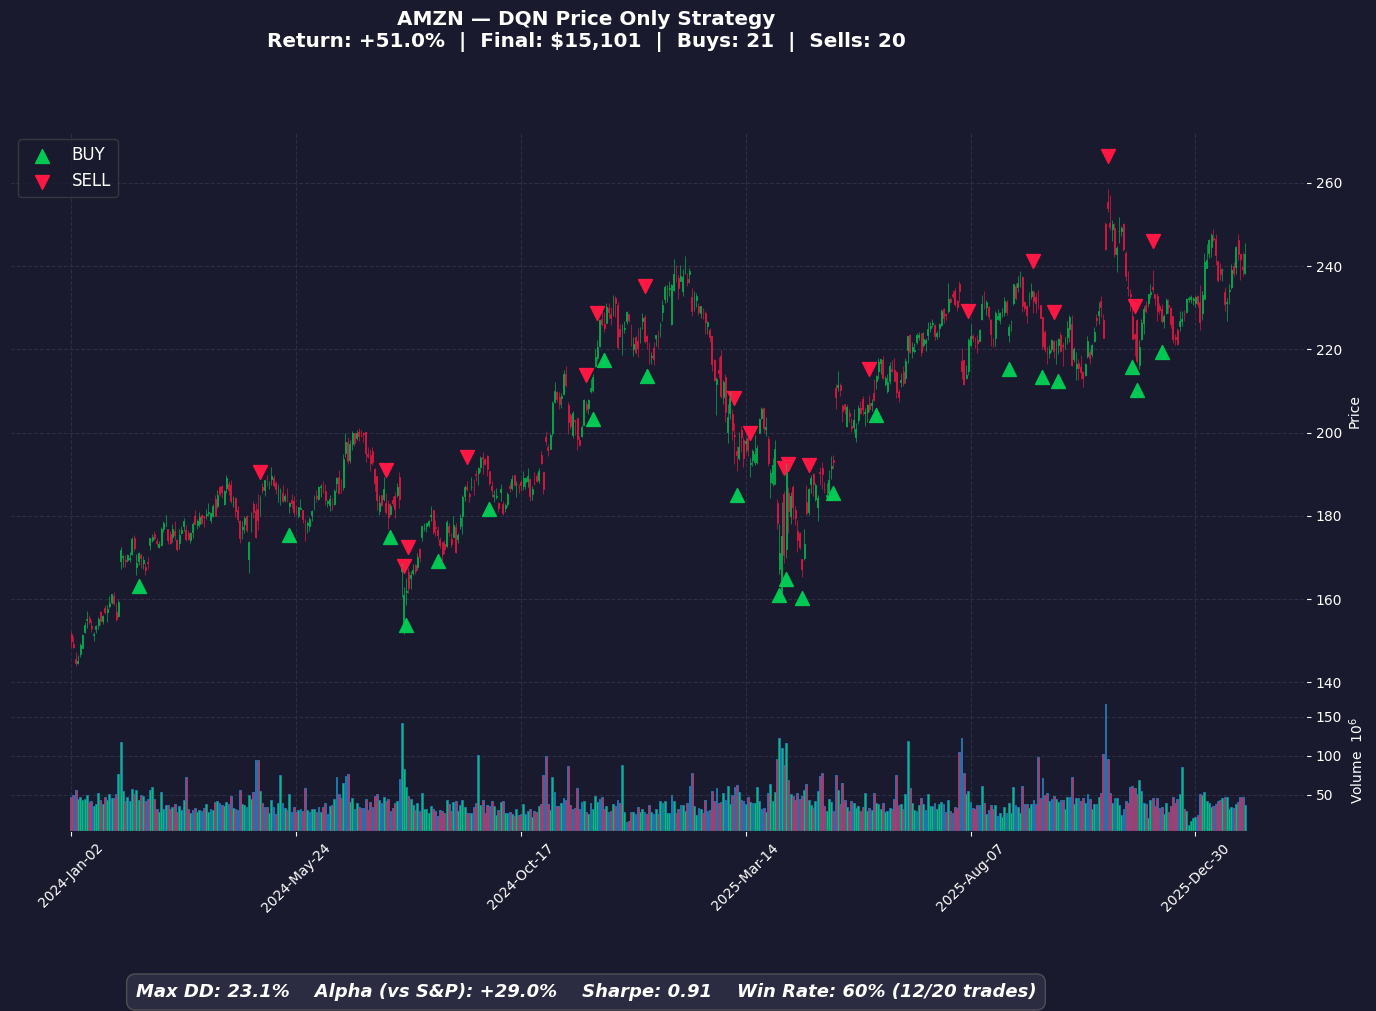

### AMZN — Trade Log (DQN Price Only)

/var/folders/pz/_0kh2t797553_kjgmmh7_0fc0000gn/T/ipykernel_25639/108095686.py:106: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  styled = log.style.applymap(


Date,Action,Price,Shares,Value,Portfolio
2024-02-14,BUY,$170.98,58,"$9,916.84","$9,990.08"
2024-05-02,SELL,$184.72,58,"$10,713.76","$10,776.29"
2024-05-21,BUY,$183.15,58,"$10,622.70","$10,765.67"
2024-07-24,SELL,$180.83,58,"$10,488.14","$10,620.62"
2024-07-26,BUY,$182.50,58,"$10,585.00","$10,610.03"
2024-08-05,SELL,$161.02,58,"$9,339.16","$9,354.85"
2024-08-06,BUY,$161.93,57,"$9,230.01","$9,345.62"
2024-08-07,SELL,$162.77,57,"$9,277.89","$9,384.23"
2024-08-26,BUY,$175.50,53,"$9,301.50","$9,374.93"
2024-09-13,SELL,$186.49,53,"$9,883.97","$9,947.51"


In [18]:
plot_ticker('AMZN', method='DQN_Price_Only')


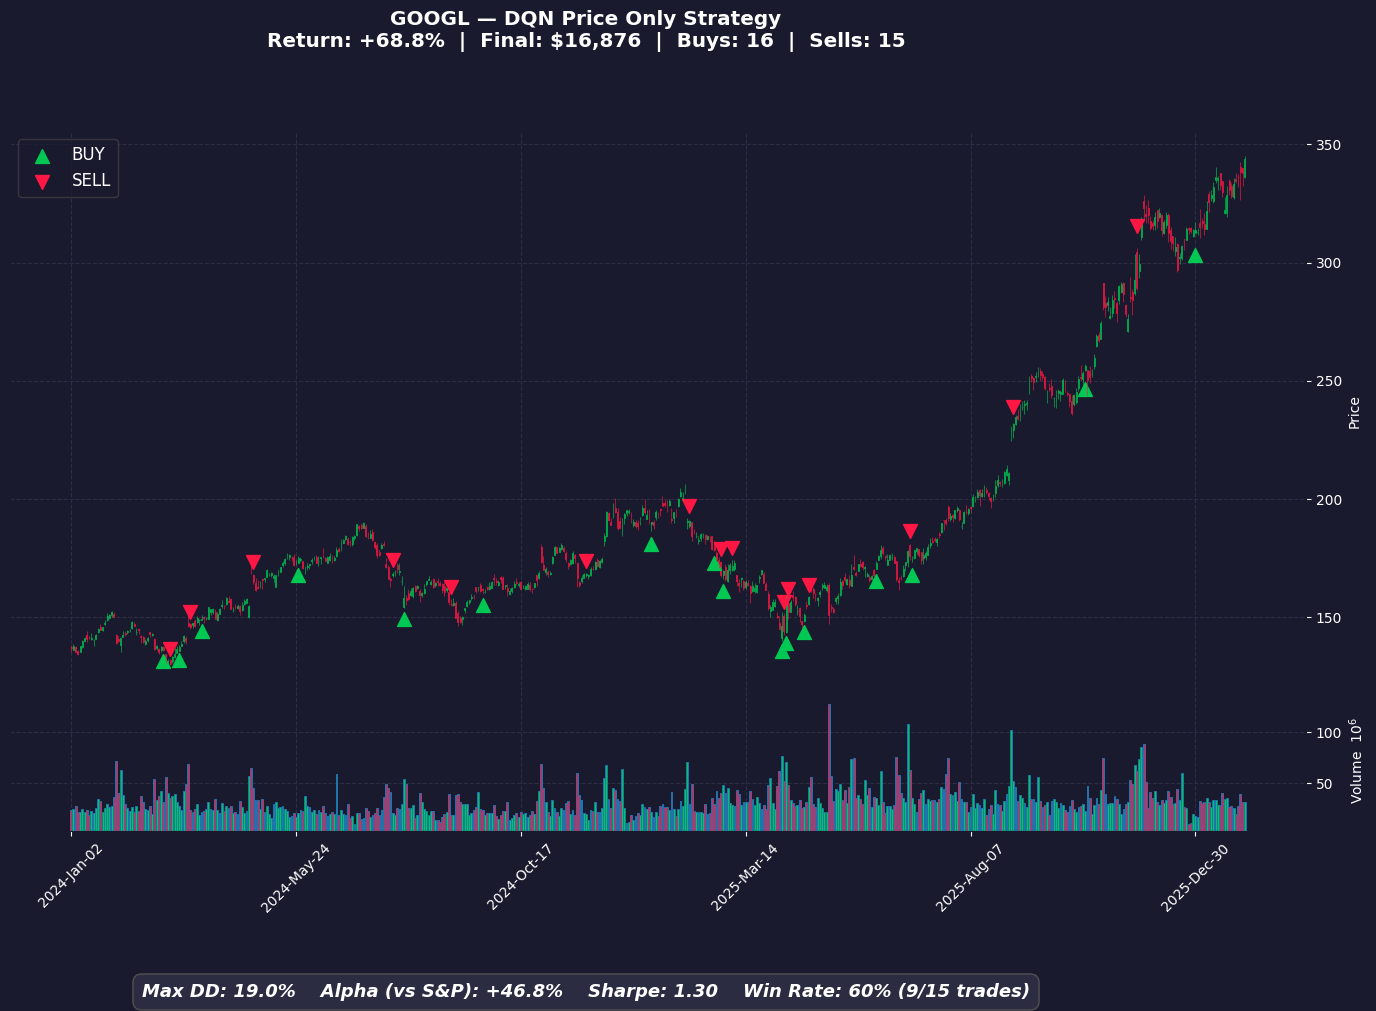

### GOOGL — Trade Log (DQN Price Only)

/var/folders/pz/_0kh2t797553_kjgmmh7_0fc0000gn/T/ipykernel_25639/108095686.py:106: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  styled = log.style.applymap(


Date,Action,Price,Shares,Value,Portfolio
2024-03-01,BUY,$136.10,73,"$9,935.53","$9,990.06"
2024-03-06,SELL,$130.41,73,"$9,519.68","$9,564.69"
2024-03-12,BUY,$137.45,69,"$9,484.25","$9,555.21"
2024-03-19,SELL,$145.92,69,"$10,068.37","$10,129.26"
2024-03-26,BUY,$149.53,67,"$10,018.57","$10,119.24"
2024-04-29,SELL,$164.89,67,"$11,047.89","$11,137.51"
2024-05-28,BUY,$175.07,63,"$11,029.18","$11,126.48"
2024-07-29,SELL,$168.44,63,"$10,611.76","$10,698.45"
2024-08-05,BUY,$158.23,67,"$10,601.19","$10,687.85"
2024-09-04,SELL,$155.44,67,"$10,414.79","$10,491.04"


In [19]:
plot_ticker('GOOGL', method='DQN_Price_Only')


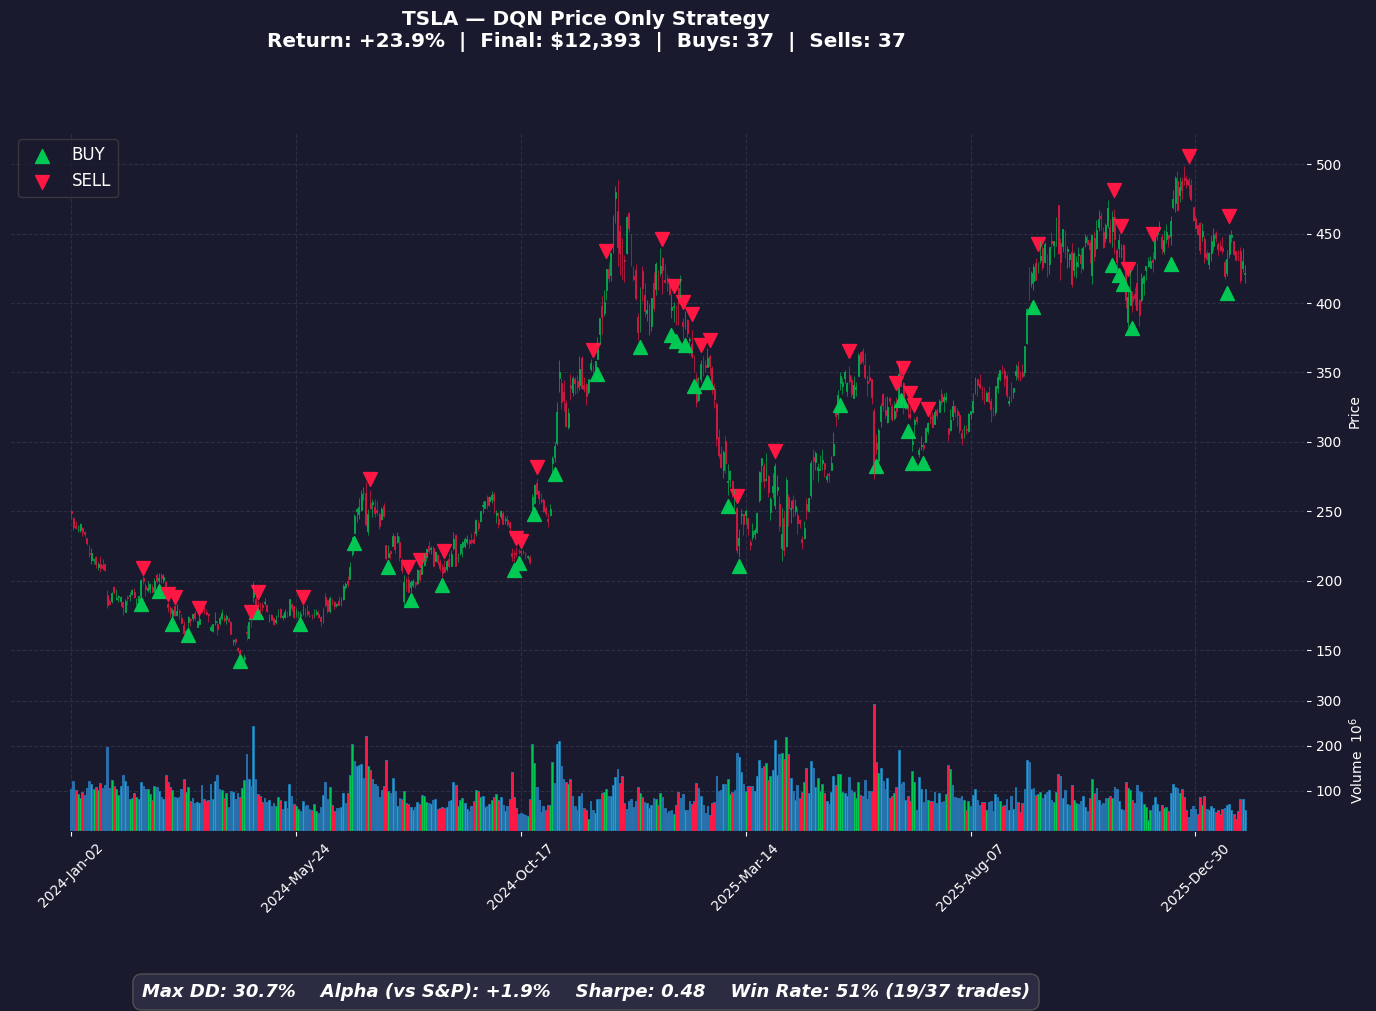

### TSLA — Trade Log (DQN Price Only)

/var/folders/pz/_0kh2t797553_kjgmmh7_0fc0000gn/T/ipykernel_25639/108095686.py:106: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  styled = log.style.applymap(


Date,Action,Price,Shares,Value,Portfolio
2024-02-15,BUY,$200.45,49,"$9,822.05","$9,990.18"
2024-02-16,SELL,$199.95,49,"$9,797.55","$9,955.88"
2024-02-28,BUY,$202.04,49,"$9,899.96","$9,945.98"
2024-03-05,SELL,$180.74,49,"$8,856.26","$8,893.42"
2024-03-07,BUY,$178.65,49,"$8,753.85","$8,884.67"
2024-03-08,SELL,$175.34,49,"$8,591.66","$8,713.89"
2024-03-18,BUY,$173.80,50,"$8,690.00","$8,705.20"
2024-03-25,SELL,$172.63,50,"$8,631.50","$8,638.07"
2024-04-19,BUY,$147.05,58,"$8,528.90","$8,629.54"
2024-04-26,SELL,$168.29,58,"$9,760.82","$9,851.70"


In [20]:
plot_ticker('TSLA', method='DQN_Price_Only')

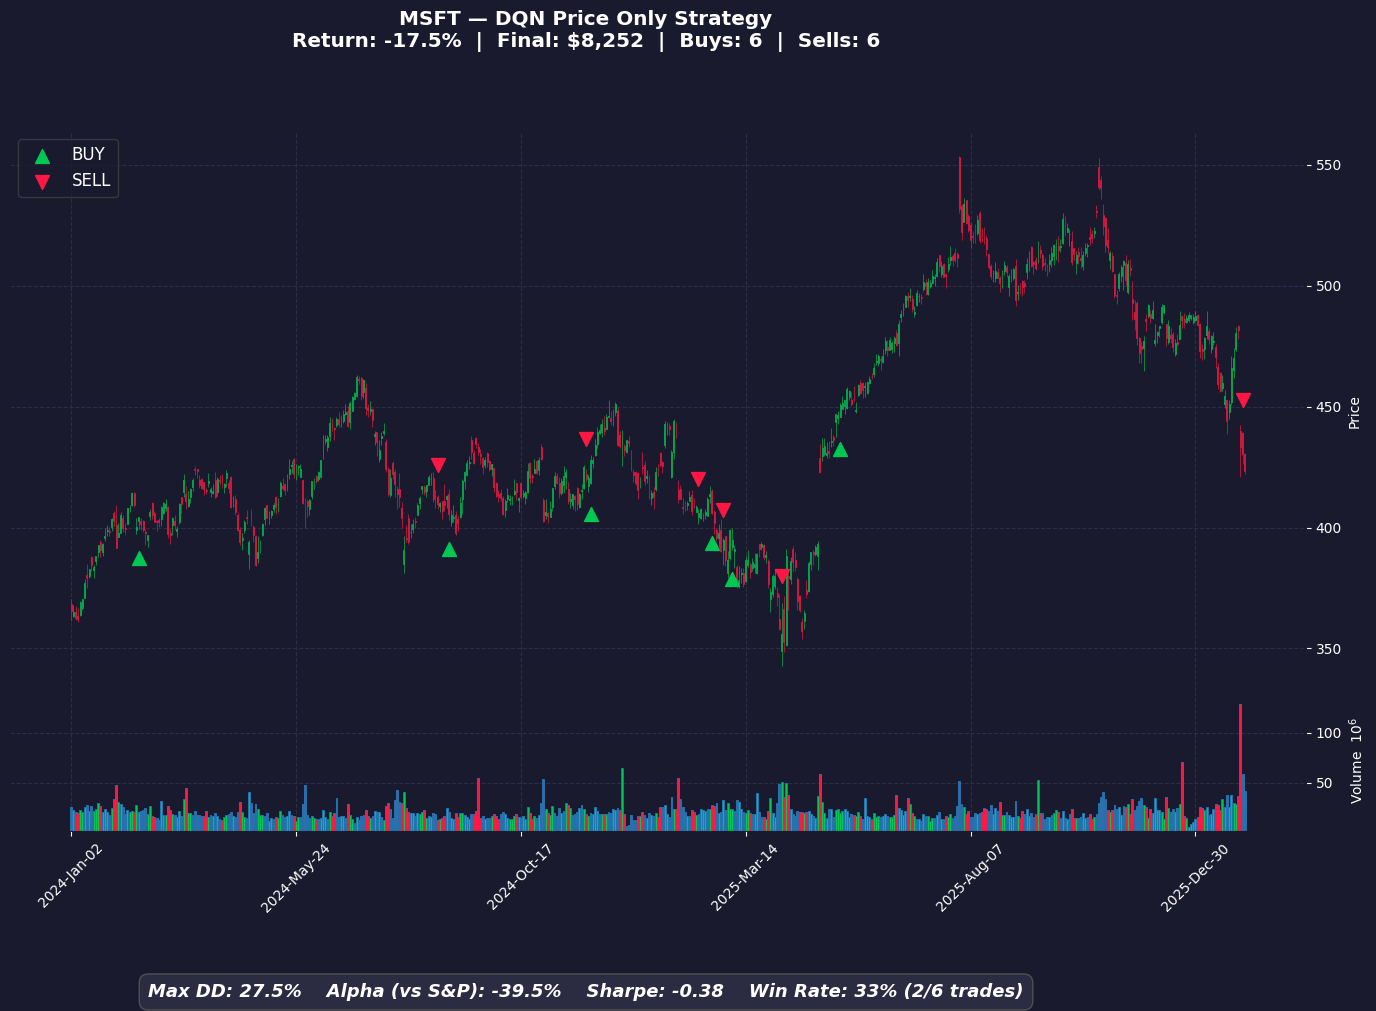

### MSFT — Trade Log (DQN Price Only)

/var/folders/pz/_0kh2t797553_kjgmmh7_0fc0000gn/T/ipykernel_25639/108095686.py:106: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  styled = log.style.applymap(


Date,Action,Price,Shares,Value,Portfolio
2024-02-14,BUY,$404.23,24,"$9,701.54","$9,990.30"
2024-08-26,SELL,$409.63,24,"$9,831.15","$10,110.08"
2024-09-03,BUY,$405.62,24,"$9,734.86","$10,100.35"
2024-11-27,SELL,$419.89,24,"$10,077.24","$10,432.65"
2024-12-02,BUY,$427.82,24,"$10,267.59","$10,422.39"
2025-02-12,SELL,$406.04,24,"$9,744.90","$9,889.95"
2025-02-21,BUY,$406.02,24,"$9,744.52","$9,880.20"
2025-02-28,SELL,$394.86,24,"$9,476.69","$9,602.89"
2025-03-06,BUY,$394.76,24,"$9,474.30","$9,593.41"
2025-04-07,SELL,$355.94,24,"$8,542.60","$8,653.17"


In [21]:
plot_ticker('MSFT', method='DQN_Price_Only')

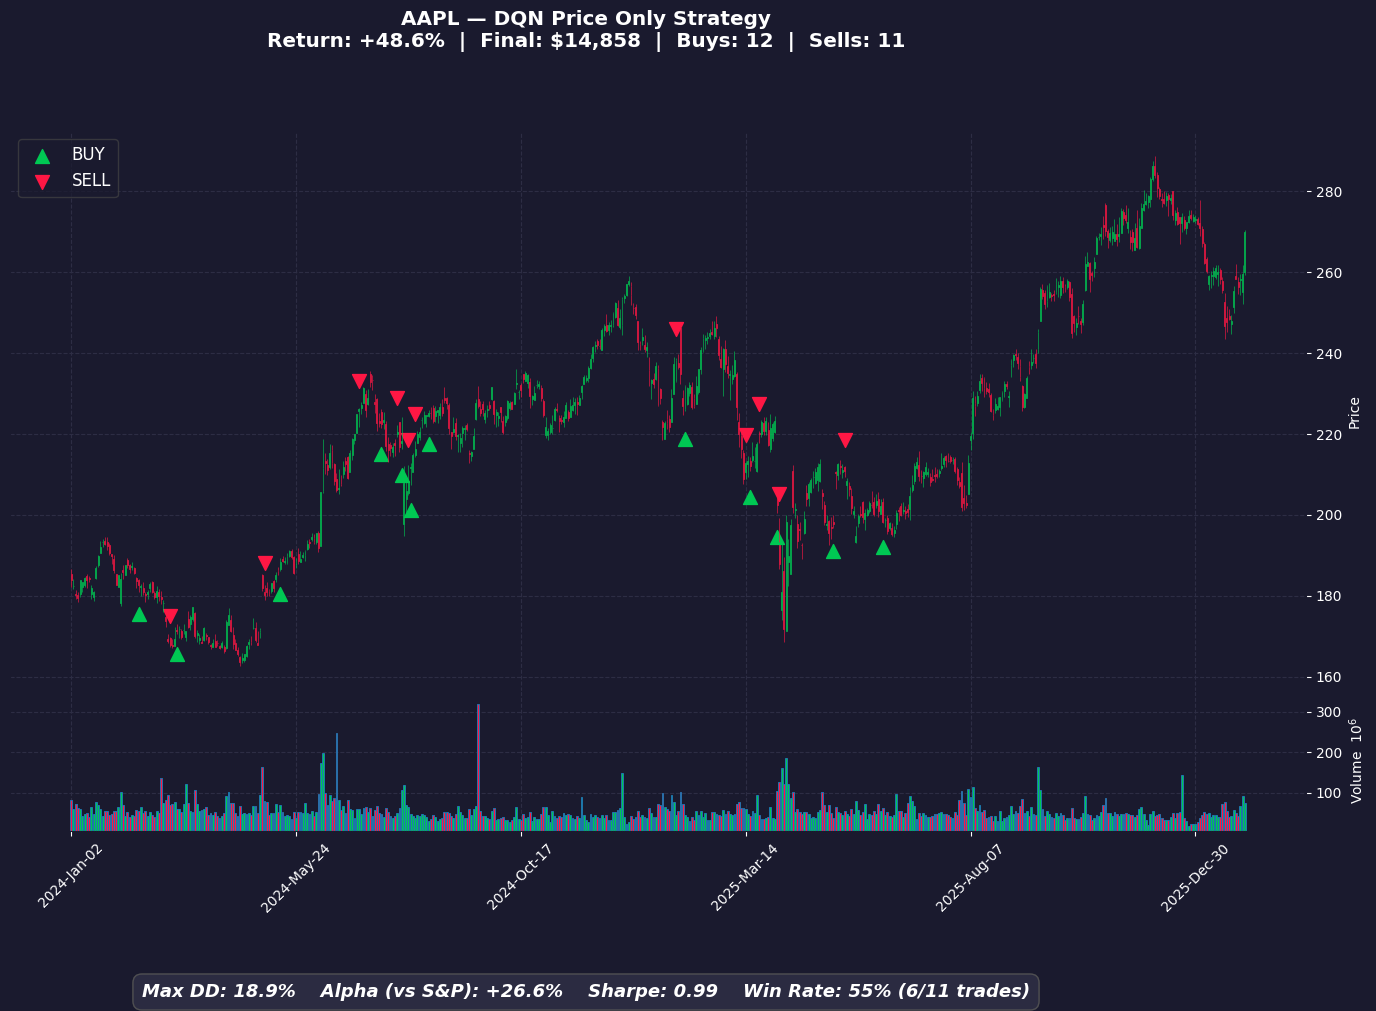

### AAPL — Trade Log (DQN Price Only)

/var/folders/pz/_0kh2t797553_kjgmmh7_0fc0000gn/T/ipykernel_25639/108095686.py:106: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  styled = log.style.applymap(


Date,Action,Price,Shares,Value,Portfolio
2024-02-14,BUY,$182.67,54,"$9,864.34","$9,990.14"
2024-03-06,SELL,$167.76,54,"$9,059.23","$9,175.97"
2024-03-11,BUY,$171.36,53,"$9,082.32","$9,166.88"
2024-05-06,SELL,$180.25,53,"$9,553.39","$9,628.40"
2024-05-15,BUY,$188.46,51,"$9,611.22","$9,618.79"
2024-07-08,SELL,$226.30,51,"$11,541.37","$11,537.40"
2024-07-22,BUY,$222.47,51,"$11,345.82","$11,526.05"
2024-07-31,SELL,$220.60,51,"$11,250.58","$11,419.56"
2024-08-02,BUY,$218.39,52,"$11,356.51","$11,408.20"
2024-08-07,SELL,$208.42,52,"$10,837.91","$10,878.77"


In [22]:
plot_ticker('AAPL', method='DQN_Price_Only')

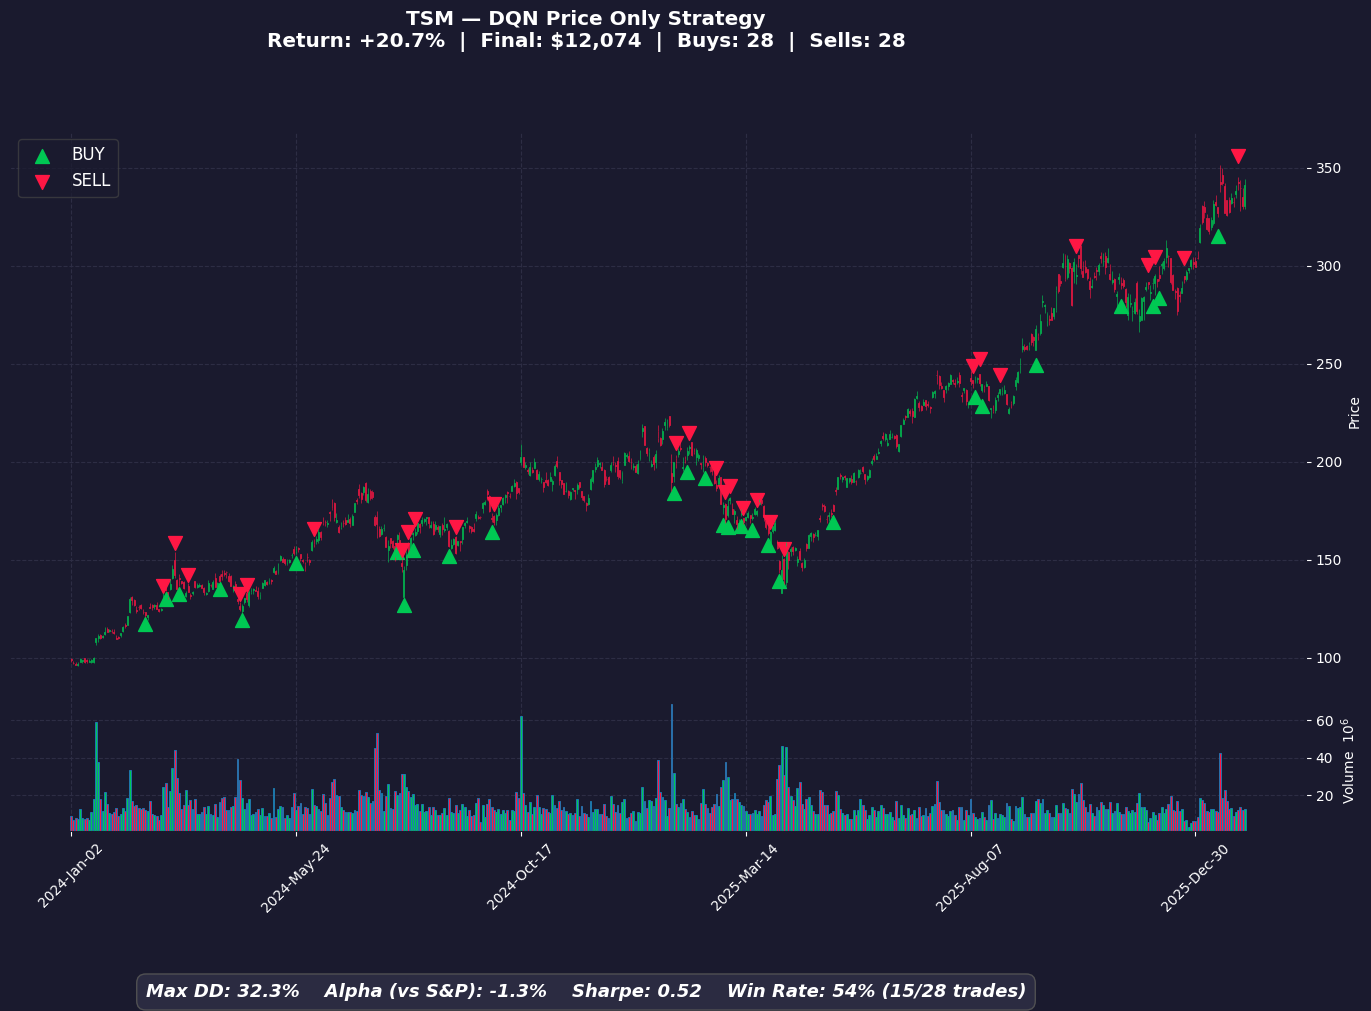

### TSM — Trade Log (DQN Price Only)

/var/folders/pz/_0kh2t797553_kjgmmh7_0fc0000gn/T/ipykernel_25639/108095686.py:106: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  styled = log.style.applymap(


Date,Action,Price,Shares,Value,Portfolio
2024-02-20,BUY,$121.97,81,"$9,879.45","$9,990.12"
2024-03-01,SELL,$130.31,81,"$10,555.00","$10,655.12"
2024-03-04,BUY,$134.55,79,"$10,629.59","$10,644.49"
2024-03-08,SELL,$142.44,79,"$11,253.09","$11,256.74"
2024-03-12,BUY,$140.53,80,"$11,242.16","$11,245.50"
2024-03-18,SELL,$133.51,80,"$10,681.11","$10,673.76"
2024-04-08,BUY,$139.52,76,"$10,603.76","$10,663.16"
2024-04-19,SELL,$124.78,76,"$9,483.16","$9,533.08"
2024-04-22,BUY,$126.78,75,"$9,508.61","$9,523.57"
2024-04-24,SELL,$129.93,75,"$9,744.59","$9,749.80"


In [23]:
plot_ticker('TSM', method='DQN_Price_Only')

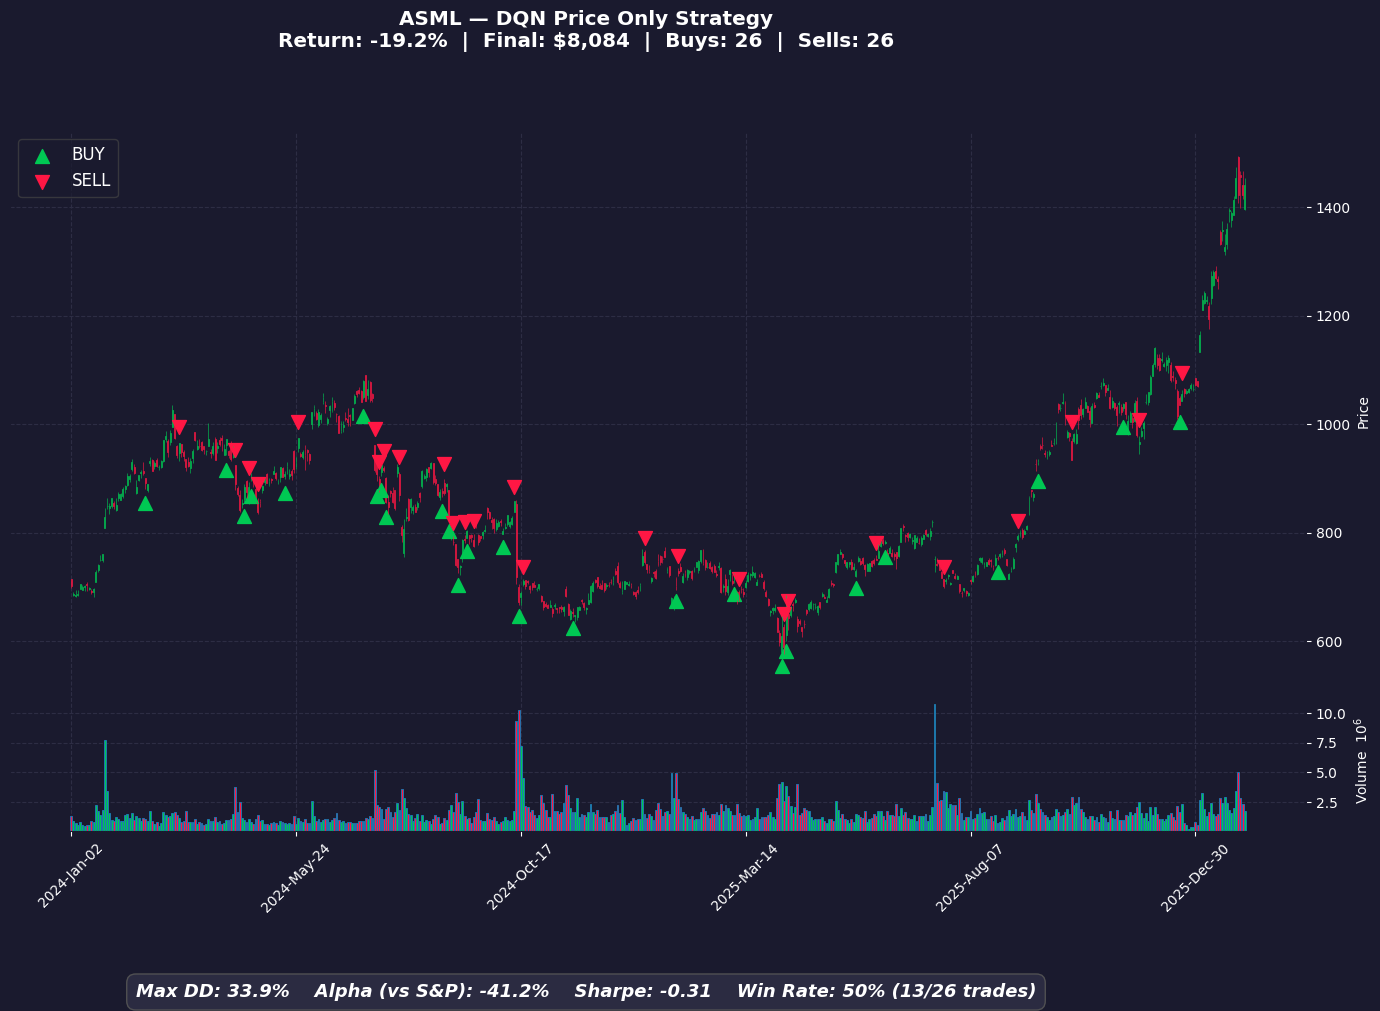

### ASML — Trade Log (DQN Price Only)

/var/folders/pz/_0kh2t797553_kjgmmh7_0fc0000gn/T/ipykernel_25639/108095686.py:106: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  styled = log.style.applymap(


Date,Action,Price,Shares,Value,Portfolio
2024-02-20,BUY,$891.62,11,"$9,807.79","$9,990.19"
2024-03-12,SELL,$964.86,11,"$10,613.48","$10,785.28"
2024-04-11,BUY,$972.60,11,"$10,698.56","$10,774.58"
2024-04-17,SELL,$889.70,11,"$9,786.65","$9,852.88"
2024-04-23,BUY,$883.77,11,"$9,721.52","$9,843.16"
2024-04-25,SELL,$884.70,11,"$9,731.66","$9,843.56"
2024-04-26,BUY,$902.67,10,"$9,026.68","$9,834.54"
2024-05-01,SELL,$837.71,10,"$8,377.11","$9,176.59"
2024-05-17,BUY,$908.56,10,"$9,085.61","$9,167.51"
2024-05-28,SELL,$974.25,10,"$9,742.55","$9,814.70"


In [24]:
plot_ticker('ASML', method='DQN_Price_Only')